# IZV cast 3.2 projektu 2025
# Autor: Smirnov Nikita (xsmirn02)

### Library import

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

### Initial settings

In [ ]:
# initial data loading
df_accidents = pd.read_pickle("accidents.pkl.gz")
df_vehicles = pd.read_pickle("vehicles.pkl.gz")

['p1', 'p2a', 'p2b', 'p4a', 'p4b', 'p4c', 'p5a', 'p6', 'p7', 'p8', 'p8a', 'p9', 'p10', 'p11', 'p11a', 'p12', 'p13a', 'p13b', 'p13c', 'p14*100', 'p15', 'p16', 'p17', 'p18', 'p19', 'p20', 'p21', 'p22', 'p23', 'p24', 'p27', 'p28', 'p34', 'p35', 'p36', 'p37', 'p38', 'p39', 'date', 'region']


## Hypothesis 1

> #### The probability of dying in an accident on a category `I` road was the same as on a category `III` road.

Also to test: whether accidents on category `I` roads led more or less frequently to accidents with health consequences(p9 == 1) than on highways(p36 == 0).

---

In column p13 we have 3 categories:
- p13a: number of died people in accident
- p13b: number of seriously injured people in accident
- p13c: number of slightly injured people in accident

Therefor we have 2 ways of analysing the probability:
1. treat accidents with `[p13a] > 0` as fatal accident and calculate probabilities based on this metric
2. calculate probability of dying per accident and work further with this metric

From here we would use names for those methods 
1. BM:  binary metric
2. PPP: per person pobability

From data analysis point of view, BM looks better. But hypotesis suits more with the PPP for the first glance. 
But due to not having number of all persons that was in incident(mainly for p9 == 1) we cant count PPP properly, therefore we have proper `Probability of dying in incedent among injured persons`. And that metric doesnt look exactly like our hypothesis, so we either can do both, or we better stick with first method.

### Data preparation

In [3]:
# Extract accidents only from road category I and III 
df_h1 = df_accidents[df_accidents['p36'].isin([1, 3])].copy()

### Preparation for BM
We would count all accidents where was at least 1 dead person as `fatal incident` 

In [4]:
# Creating column for BM
df_h1['fatal'] = (df_h1['p13a'] > 0)

# Names for p36 for prettier output
df_h1['road_name'] = df_h1['p36'].map({1: 'Road I class', 3: 'Road III class'})

# Gather statistics
print("Classification by road class:")
print(df_h1['road_name'].value_counts())

# Preparation for highway injured rate analysis
df_highway = df_accidents[df_accidents['p36'] == 0].copy()

print(f"\nNumber of accidents on highways: {len(df_highway)}")

Classification by road class:
road_name
Road III class    34386
Road I class      32123
Name: count, dtype: int64

Number of accidents on highways: 11850


In [5]:
# Process data for I and III road class
summary = df_h1.groupby('road_name').agg({
    'fatal': ['sum', 'count'],
    'p9': lambda x: (x == 1).sum()
})
summary.columns = ['Fatal accidents', 'Number of accidents', 'With consequnces']
summary['Proportion of fatals (%)'] = (summary['Fatal accidents'] / summary['Number of accidents'] * 100)
summary['Proportion with consequences(%)'] = (summary['With consequnces'] / summary['Number of accidents'] * 100)

display(summary[['Number of accidents', 'Fatal accidents', 'Proportion of fatals (%)']])

,Number of accidents,Fatal accidents,Proportion of fatals (%)
road_name,,,
Road I class,32123,359,1.117579
Road III class,34386,208,0.604897


In [6]:
# Process injuries rate for highways
highway_total = len(df_highway)
highway_injuries = (df_highway['p9'] == 1).sum()
highway_injuries_rate = highway_injuries / highway_total * 100

print("Highway accidents:")
print(f"\tNumber of accidents:\t{highway_total}")
print(f"\tWith consequnces:\t{highway_injuries} ({highway_injuries_rate:.2f}%)")

Highway accidents:
	Number of accidents:	11850
	With consequnces:	1940 (16.37%)


In [7]:
# contingency table
contingency = pd.crosstab(df_h1['road_name'], df_h1['fatal'])
contingency.columns = ['Nonfatal', 'Fatal']

display(contingency)

,Nonfatal,Fatal
road_name,,
Road I class,31764,359
Road III class,34178,208


In [8]:
chi2, p_val, dof, expected = stats.chi2_contingency(contingency.to_numpy())
print("Results of chi2 test\n")

print(f"chi2 statistics:\t\t{chi2:.2f}")
print(f"p-value:\t\t\t{p_val:.15f}")
print(f"Degrees of freedom:\t\t{dof}")
print(f"Critical value:\t\t\t{stats.chi2.ppf(0.95, dof):.2f}")

Results of chi2 test

chi2 statistics:		51.04
p-value:			0.000000000000905
Degrees of freedom:		1
Critical value:			3.84


### Chi2 results
As we can see p_val < 0.05 => our hypotesis H_0:
> The probability of dying in an accident on a category `I` road was the same as on a category `III` road.

With more than 95% probabililty is false. Also differnce between road `I` and `III` class is over 50% that much bigger than critical value.

In [9]:
# Expected frequencies
expected_df = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)
print("Expected frequencies")
print("Assuming H_0 (fatal probability on road I class ~ fatal probability on road class 3):")
display(expected_df.round(2))

Expected frequencies
Assuming H_0 (fatal probability on road I class ~ fatal probability on road class 3):


,Nonfatal,Fatal
road_name,,
Road I class,31849.15,273.85
Road III class,34092.85,293.15


In [10]:
# Deviations
print("comparisonof observed and expected values:")
obs = contingency.to_numpy()
for i, road in enumerate(contingency.index):
    obs_fatal = obs[i, 1]
    exp_fatal = expected[i, 1]
    diff = obs_fatal - exp_fatal
    rel_diff = (diff / exp_fatal * 100)
    print(f"\t{road}:\tobs={obs_fatal}, exp={exp_fatal:.2f}, diff={diff:.2f} ({rel_diff:.2f}%)")

comparisonof observed and expected values:
	Road I class:	obs=359, exp=273.85, diff=85.15 (31.09%)
	Road III class:	obs=208, exp=293.15, diff=-85.15 (-29.05%)


### Additional analysis: comparison I road class with highways

Task provides information about this test as
> ...s tím, že také určíte, jestli nehody na silnicích 1. třídy vedly častěji či méně často k nehodě s následky na zdraví než na dálnicích. V tom vám může pomoct “expected” výstup 𝜒2 testu.

If I understand this correctly, we dont need to make another chi2 test. But we cant use results in expected output from first chi2 test due to not having such a metric. So, we either need to:
- Use injury rate as chi2 metric and sort out fatal incidents from after for hypotesis prooving (what sounds totaly incorect from data analysis point of view)
- Use our precalculated value for injuries rate `Proportion with consequences(%)`

Therefore we will stick with second variant

In [11]:
# Porovnani nasledku na zdravi (p9)
injuries_road1 = summary.loc['Road I class', 'Proportion with consequences(%)']
injuries_highway = highway_injuries_rate

print(f"Incidents with injuries:")
print(f"\tRoad I class:\t{injuries_road1:.2f}%")
print(f"\tHighways:\t{injuries_highway:.2f}%")
print(f"\tDifference:\t{injuries_road1 - injuries_highway:.2f}%")

Incidents with injuries:
	Road I class:	33.91%
	Highways:	16.37%
	Difference:	17.54%


### Incedents followed by injuries happened less frequently on highways by 17.54%  

Due to such big difference, and due to this test being "additional analysis", I dont think we need to prove that this result is valid, beside the correct computation of those values. 

### Visual confirmation of aquired data

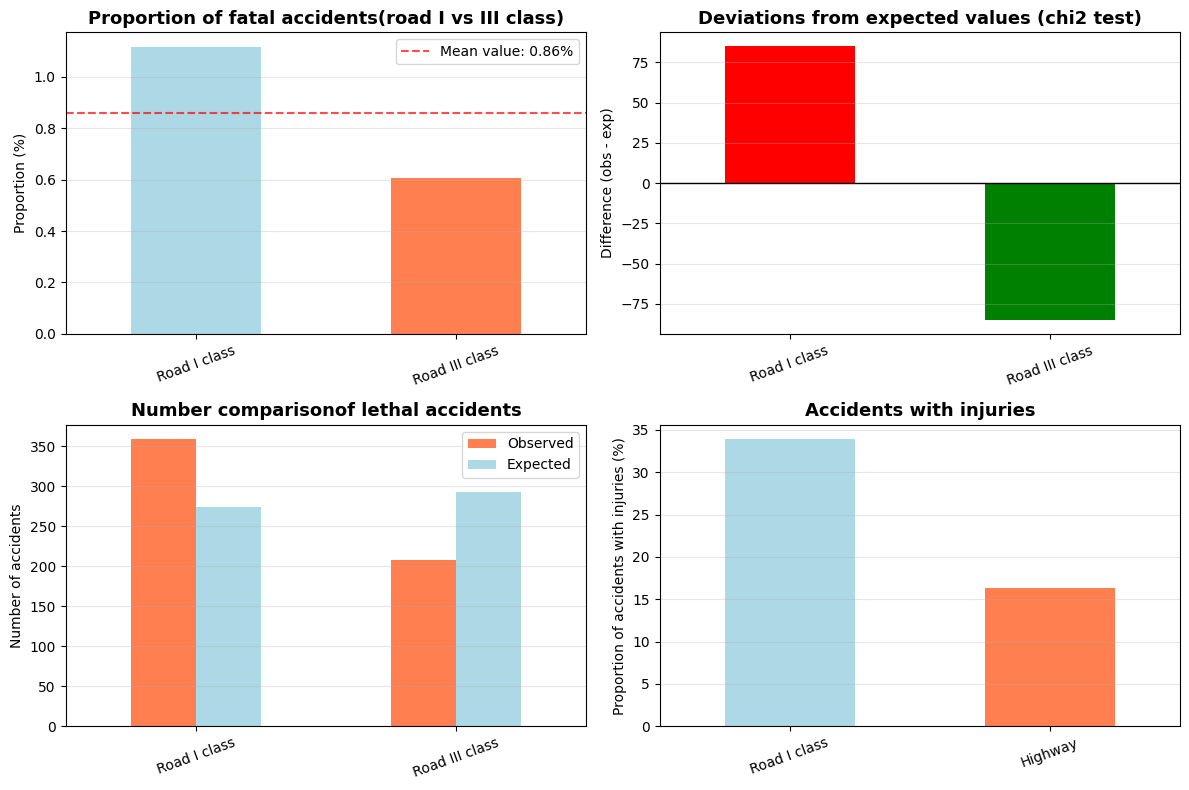

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Plot 1: comparison in lethal metric beetween Road I and III class
rates_1_3 = pd.Series({
    'Road I class':     summary.loc['Road I class', 'Proportion of fatals (%)'],
    'Road III class':   summary.loc['Road III class', 'Proportion of fatals (%)']
})
rates_1_3.plot(kind='bar', ax=axes[0, 0], color=['lightblue', 'coral'])
axes[0, 0].set_title('Proportion of fatal accidents(road I vs III class)', fontsize=13, weight='bold')
axes[0, 0].set_ylabel('Proportion (%)')
axes[0, 0].axhline(y=rates_1_3.mean(), color='red', linestyle='--', alpha=0.7,
                   label=f'Mean value: {rates_1_3.mean():.2f}%')
axes[0, 0].legend()

# Plot 2: Deviations from expected values (from chi2 test)
deviations = contingency['Fatal'].values - expected[:, 1]
pd.Series(deviations, index=contingency.index).plot(kind='bar', ax=axes[0, 1], color=['red', 'green'])
axes[0, 1].set_title('Deviations from expected values (chi2 test)', fontsize=13, weight='bold')
axes[0, 1].set_ylabel('Difference (obs - exp)')
axes[0, 1].axhline(y=0, color='black', linestyle='-', linewidth=1)

# Plot 3: Deviations from expected values 2Var (from chi2 test)
comparison = pd.DataFrame({
    'Observed': [summary.loc['Road I class', 'Fatal accidents'], summary.loc['Road III class', 'Fatal accidents']],
    'Expected': [expected[0, 1], expected[1, 1]]
}, index=['Road I class', 'Road III class'])

comparison.plot(kind='bar', ax=axes[1, 0], color=['coral', 'lightblue'])
axes[1, 0].set_title('Number comparisonof lethal accidents', fontsize=13, weight='bold')
axes[1, 0].set_ylabel('Number of accidents')
axes[1, 0].legend()

# Plot 4: Accidents with injuries (road I class vs highways)
casualties_comp = pd.Series({
    'Road I class': injuries_road1,
    'Highway': injuries_highway
})
casualties_comp.plot(kind='bar', ax=axes[1, 1], color=['lightblue', 'coral'])
axes[1, 1].set_title('Accidents with injuries', fontsize=13, weight='bold')
axes[1, 1].set_ylabel('Proportion of accidents with injuries (%)')

for ax1 in axes:
    for ax2 in ax1:
        ax2.grid(axis='y', alpha=0.3)
        ax2.set_xticklabels(ax2.get_xticklabels(), rotation=20, ha='center')
        ax2.set_xlabel('')

plt.tight_layout()
plt.show()

### Conclusion

#### Hypotesis 1:

> Hypotesis H_0: The probability of dying in an accident on a category `I` road was the same as on a category `III` road.

#### Results of chi2 test:
- chi2 = 51.04, p-value < 0.05
- p-value is **significantly lower** than needed 0.05
- Critical value: 3.84
- H_0 **Rejected**

#### Interpretation:

The obtained chi2 statistic (51.04) is far above the critical value (3.84), therefore the H_0 is rejected.

But acquired values differs from expected by:
- Road I class:     +85.15 actual fatal accidents (+31.09%)
- Road III class:   -85.15 actual fatal accidents (-29.05%)

So, H_0 **is not** valid

#### Additional analysis: comparison I road class with highways:
**Incidents with injuries:**
- Accidents on road I class end up with injuries in **33.91%** of the cases 
- Accidents on highways end up with injuries in **16.37%** of the cases
- Difference: **+17.54%**

Or, in another words, we can see that accidents with injuries happens on highways **more than twice** less frequently than on road I class.

## Hypothesis 2

> #### The damage caused by accidents involving brand `X` is lower than that caused by accidents involving brand `Y`, and this difference is statistically significant.

Let:
- H_0 - The damage caused by accidents involving brand `X` is lower than that caused by accidents involving brand `Y`, and this difference is statistically significant.
- H_1 - The damage caused by accidents involving brand `X` is **NOT** lower than that caused by accidents involving brand `Y`, and this difference is statistically significant.
- H_2 - The damage caused by accidents involving brand `X` is differs from that caused by accidents involving brand `Y`, and this difference is **NOT** statistically significant.

Further description for selected brands: 

Due to high dispertion and not normilized data we cant decide about good candidates only by avg or mean value. After trying to find them by hand there was wrote simple script that found best candidate pairs for H_2 that was used further in code - VOLVO vs PEUGEOT.

### Data preparation and brand selection

In [13]:
print("Top brands by number of accidents")
print(df_vehicles['p45a'].value_counts().sort_values(ascending=False))

# Mapping for used brands
brand_map = {
    39: 'ŠKODA',
    # 44: 'TOYOTA',
    48: 'VOLVO', 
    # 47: 'VOLKSWAGEN',
    # 13: 'FORD',
    26: 'MERCEDES',
    # 35: 'RENAULT',
    32: 'PEUGEOT',
}

df_veh = df_vehicles[df_vehicles['p45a'].isin(brand_map.keys())].copy()
# df_veh = df_veh[df_veh['p53'] > 0].copy()
df_veh['brand'] = df_veh['p45a'].map(brand_map)

print(f"\nNumber of accidents: {len(df_veh)}")
print(f"By brand:")
print(df_veh['brand'].value_counts().sort_values(ascending=False))

Top brands by number of accidents
p45a
39.0    93551
0.0     65369
47.0    37166
13.0    19590
26.0    16282
        ...  
69.0        1
66.0        1
52.0        1
67.0        1
56.0        1
Name: count, Length: 95, dtype: int64

Number of accidents: 129073
By brand:
brand
ŠKODA       93551
MERCEDES    16282
PEUGEOT     12238
VOLVO        7002
Name: count, dtype: int64


### Gather statistics about chosen brands

In [14]:
brand_stats = df_veh.groupby('brand')['p53'].agg([
    'count', 'mean', 'median', 'std'
]).round(0)
brand_stats.columns = ['Number of accidents', 'Average damage', 'Median damage', 'Standard deviation']
brand_stats = brand_stats.sort_values('Average damage', ascending=False)

display(brand_stats)

,Number of accidents,Average damage,Median damage,Standard deviation
brand,,,,
MERCEDES,16282,765.0,300.0,1847.0
VOLVO,7002,662.0,300.0,1370.0
ŠKODA,93551,494.0,300.0,705.0
PEUGEOT,12238,416.0,250.0,751.0


### Gathered statistics analysis

As we can see, we have `median` value 300 in almost every brand, that means 30.000Kč is some sort of minimal value for damage or standart value if damage has been done.

Also we can see quite a big deviation, and in some cases avarage damage differs a lot.

Right now we can choose pairs only by average damage, In our case - `ŠKODA vs MERCEDES` candidate for prooving H_0 hypotesis and `VOLVO vs PEUGEOT` as candidate where we cant proove hypotesis with at least 95%(as was mentioned they were selected by script).

Ofcourse due to such inconsistent data we need to visualize them in order to figure out what exactly values looks like.

### Visual analysis of distribution

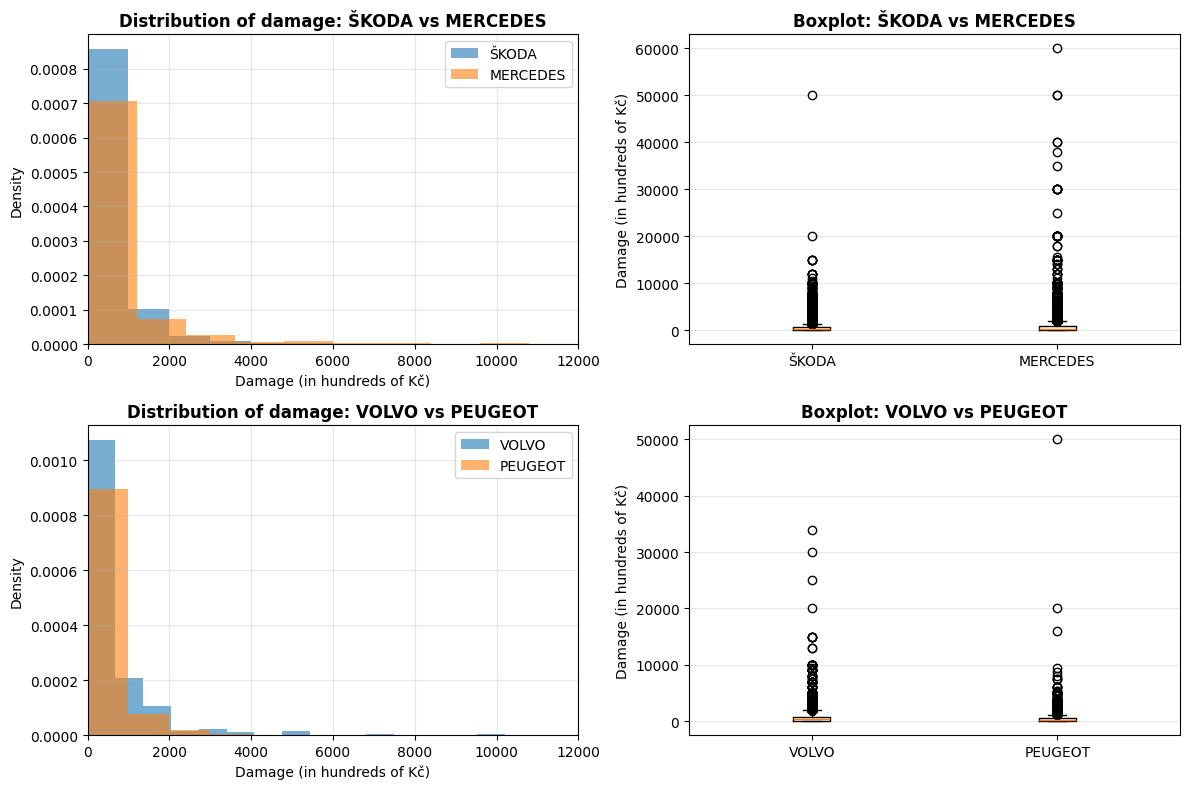

In [15]:
compare_brands = [['ŠKODA', 'MERCEDES'], ['VOLVO', 'PEUGEOT']]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, brand_pair in enumerate(compare_brands):
    # Histogram - pair 1
    for brand in brand_pair:
        data = df_veh[df_veh['brand'] == brand]['p53']
        axes[i, 0].hist(data, bins=50, alpha=0.6, label=brand, density=True)
    axes[i, 0].set_title(f'Distribution of damage: {" vs ".join(brand_pair)}', 
                         fontsize=12, weight='bold')
    axes[i, 0].set_xlabel('Damage (in hundreds of Kč)')
    axes[i, 0].set_ylabel('Density')
    axes[i, 0].legend()
    axes[i, 0].set_xlim(0, 12000)
    axes[i, 0].grid(alpha=0.3)
    
    # Boxplot - pair 1
    data_box_1 = [df_veh[df_veh['brand'] == b]['p53'].values 
                  for b in brand_pair]
    axes[i, 1].boxplot(data_box_1, tick_labels=brand_pair)
    axes[i, 1].set_title(f'Boxplot: {" vs ".join(brand_pair)}', 
                         fontsize=12, weight='bold')
    axes[i, 1].set_ylabel('Damage (in hundreds of Kč)')
    axes[i, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Visualization analysis
(x axis on first plots for each brand was limited due to high dispersion)

Summary from text and visualization analysis:
- Avarage damage differs a lot
- Mean values and boxplot visualization shows that 50% of data is very similar in every brand and lies in the very bottom of actual data dispertion  
- Dispertion of values differs a lot
- We have too much outliers 
- Right tails(or in our case up tails) is very big
- Data is not normalized

---

### Test selection

The test that suits this situation the most - **Mann-Whitheny U test**

Due to:
- Dont require data to be normilized
- Works with assymetrical distribution
- Works well with big amount of outliers 
- Pretty common test(I'm trying not to reinvent the wheel)

We use parameter alternative='less' to proove our hypotesis. For H_0

### Test 1: MERCEDES vs ŠKODA

In [16]:
print(f"TEST 1: {compare_brands[0][0]} vs {compare_brands[0][1]}")

data1 = df_veh[df_veh['brand'] == compare_brands[0][0]]['p53'].values
data2 = df_veh[df_veh['brand'] == compare_brands[0][1]]['p53'].values

u_stat, p_val = stats.mannwhitneyu(data1, data2, alternative='less')

print(f"Results:")
print(f"\tU-value: {u_stat:,.0f}")
print(f"\tp-value: {p_val:.5f}")

print(f"\nAvarage damage (in hundreds of Kč)")
print(f"\tŠKODA:    {brand_stats.loc['ŠKODA', 'Average damage']}")
print(f"\tMERCEDES: {brand_stats.loc['MERCEDES', 'Average damage']}")

TEST 1: ŠKODA vs MERCEDES
Results:
	U-value: 776,107,788
	p-value: 0.99995

Avarage damage (in hundreds of Kč)
	ŠKODA:    494.0
	MERCEDES: 765.0


#### Test 1 results:
With more than 95% confidence we can say that H_0 is true between ŠKODA and MERCEDES. The result is statistically significant.
> The damage caused by accidents involving `ŠKODA` is lower than that caused by accidents involving `MERCEDES`, and this difference is statistically significant.

### Test 2: FORD vs OPEL

In [17]:
print(f"TEST 2: {compare_brands[1][1]} vs {compare_brands[1][0]}")

data1 = df_veh[df_veh['brand'] == compare_brands[1][1]]['p53'].values
data2 = df_veh[df_veh['brand'] == compare_brands[1][0]]['p53'].values

u_stat, p_val = stats.mannwhitneyu(data1, data2, alternative='less')

print(f"Results:")
print(f"\tU-value: {u_stat:,.0f}")
print(f"\tp-value: {p_val:.5f}")

print(f"\nAvarage damage (in hundreds of Kč)")
print(f"\tPEUGEOT: {brand_stats.loc['PEUGEOT', 'Average damage']}")
print(f"\tVOLVO:   {brand_stats.loc['VOLVO', 'Average damage']}")

TEST 2: PEUGEOT vs VOLVO
Results:
	U-value: 42,690,086
	p-value: 0.33720

Avarage damage (in hundreds of Kč)
	PEUGEOT: 416.0
	VOLVO:   662.0


#### Test 2 results:
H_2 is true. Due to p-val being in `[0.05, 0.95]`

We cant decide with average damage if PEUGEOT is really cheaper than VOLVO/the difference isnt statistically significant.